# 18 — Global decorations: night, distortion and tiles

Three decorations that belong to the whole globe rather than to a data layer: `nightshade` shades the night side
at an instant, `tissot` makes a projection's distortion visible, and `basemap` pulls XYZ tiles in under the map.

API: [`Map.nightshade`](../reference/static_map.md), [`Map.tissot`](../reference/static_map.md),
[`Map.basemap`](../reference/static_map.md).

> **Where this data comes from.** Everything in this notebook is real, downloaded with
> [earthlens](https://github.com/serapeum-org/earthlens) and committed under `examples/data/`:
> WorldPop population grids, OpenStreetMap roads, GBIF bird occurrences and geoBoundaries admin
> polygons. `examples/data/ATTRIBUTION.md` records each source and its licence.


**Setup** — plus `datetime`, which `nightshade` needs.

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
from pyramids.dataset import Dataset
from pyramids.feature import FeatureCollection

from digitalearth.static import Map

# The notebook's own folder is the kernel's working directory, so the bundled
# example data sits two levels up: docs/examples -> repo root.
DATA = Path("../../examples/data")

# UTM zone 32N: a metric CRS, correct for south-west Germany.
UTM32 = 25832

import datetime as dt


## `nightshade` — the terminator at an instant

`nightshade(when)` shades the hemisphere in darkness at a given moment. Pass a **timezone-aware** `datetime`:
the terminator's position depends on the exact instant, so a naive one is an invitation to be an hour out.

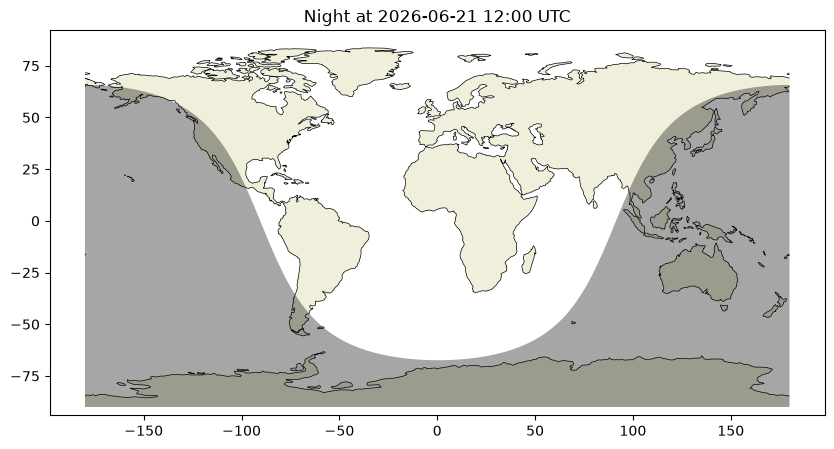

In [2]:
solstice_noon = dt.datetime(2026, 6, 21, 12, 0, tzinfo=dt.timezone.utc)

m = Map(crs=4326, figsize=(10, 5))
m.set_global()
m.coastlines()
m.land()
m.nightshade(solstice_noon)
m.set_title(f"Night at {solstice_noon:%Y-%m-%d %H:%M} UTC")
m.fig;

At the June solstice the terminator tilts hard: the Arctic is in full daylight while night reaches far over
Antarctica. That tilt *is* the solstice — it is what produces polar day and polar night.

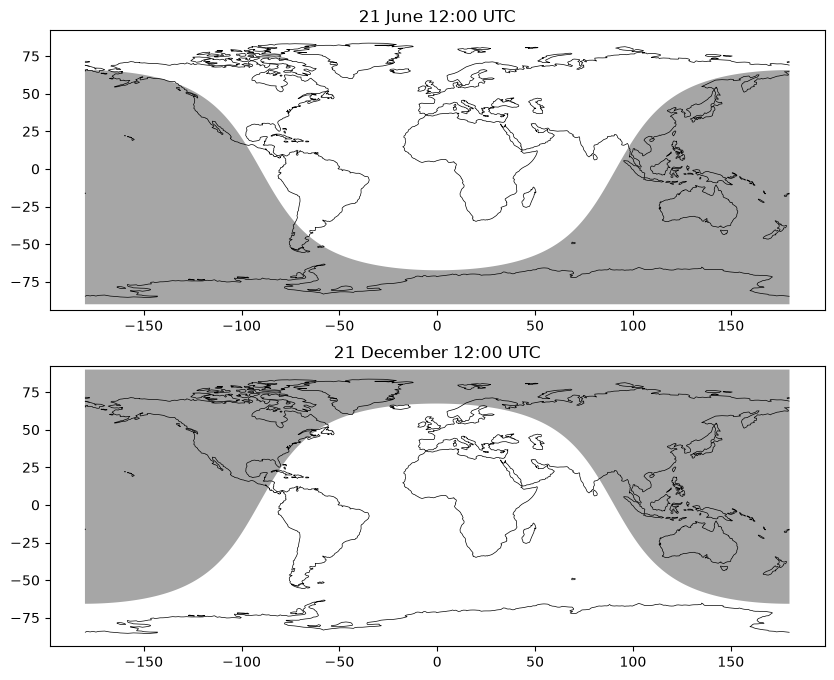

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
for ax, when in zip(axes, (solstice_noon, solstice_noon.replace(month=12, day=21))):
    panel = Map(ax=ax, crs=4326)
    panel.set_global()
    panel.coastlines()
    panel.nightshade(when)
    ax.set_title(f"{when:%d %B} 12:00 UTC")
fig;

The two terminators are mirror images about the equator. `refraction` (default `-0.83°`) sets the sun altitude
counted as sunset — the standard allowance for atmospheric bending — and `n` controls how finely the curve is
sampled.

## `tissot` — making projection distortion visible

Every flat map of a sphere distorts. Tissot's indicatrices make that concrete: circles of **one true ground
radius**, drawn where the projection puts them. Where a circle is drawn large, or as an ellipse, the map is
exaggerating.

| argument | meaning | typical value |
|---|---|---|
| `lons`, `lats` | where to place the circles | sequences of degrees |
| `radius_m` | true ground radius of each circle | `500_000` (500 km) default |
| `n` | points per circle | `64` |

In [4]:
lons = [-150, -90, -30, 30, 90, 150]
lats = [-60, -30, 0, 30, 60]
grid_lons = [lon for lat in lats for lon in lons]
grid_lats = [lat for lat in lats for lon in lons]
print(f"{len(grid_lons)} indicatrices, 800 km true radius each")

30 indicatrices, 800 km true radius each


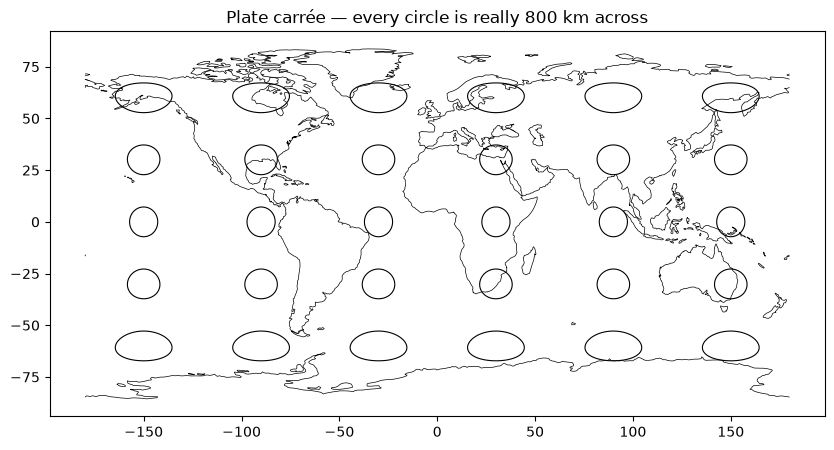

In [5]:
m = Map(crs=4326, figsize=(10, 5))
m.set_global()
m.coastlines()
m.tissot(grid_lons, grid_lats, radius_m=800_000)
m.set_title("Plate carrée — every circle is really 800 km across")
m.fig;

In plate carrée the circles keep their width in degrees but cover shrinking ground toward the poles, so the
high-latitude ones are drawn far too large. That is the familiar "Greenland looks enormous" error, measured
rather than asserted.

Put the same circles on an equal-area projection and the distortion moves: areas are preserved, so the circles
keep their size while their *shape* skews.

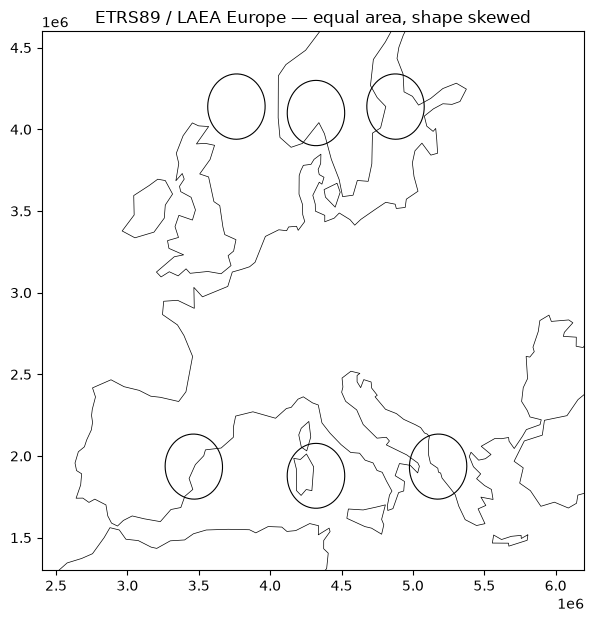

In [6]:
m = Map(crs=3035, figsize=(7, 7))
m.coastlines()
m.tissot([0, 10, 20, 0, 10, 20], [40, 40, 40, 60, 60, 60], radius_m=200_000)
m.set_bounds([2.4e6, 1.3e6, 6.2e6, 4.6e6])   # EPSG:3035 is metres, not degrees
m.set_title("ETRS89 / LAEA Europe — equal area, shape skewed")
m.fig;

This is the trade every projection makes, and `tissot` is how to see which trade you chose. Reach for it whenever
the projection is doing real work — an area comparison, a distance claim — rather than just framing a picture.

## `basemap` — XYZ tiles under the map

`basemap()` fetches raster tiles and draws them beneath everything else, in the display CRS. **It needs network
access**; offline it is skipped rather than raising, so a notebook stays runnable either way.

Tiles are served in Web Mercator, so EPSG:3857 is the CRS that needs no resampling — which also
means `set_bounds` here takes **metres**, not degrees. Framing on the data with `padding=` sidesteps
the conversion; passing degrees to a 3857 map silently frames a sub-metre box at Null Island, and
`basemap()` then fetches zoom-19 tiles of the Atlantic.

In [7]:
roads = FeatureCollection.read_file(str(DATA / "heidelberg_roads.geojson"))
arterials = FeatureCollection(roads[roads["klass"].isin(["trunk", "primary", "secondary"])])
print(f"{len(arterials)} arterial segments to draw over the tiles")

812 arterial segments to draw over the tiles


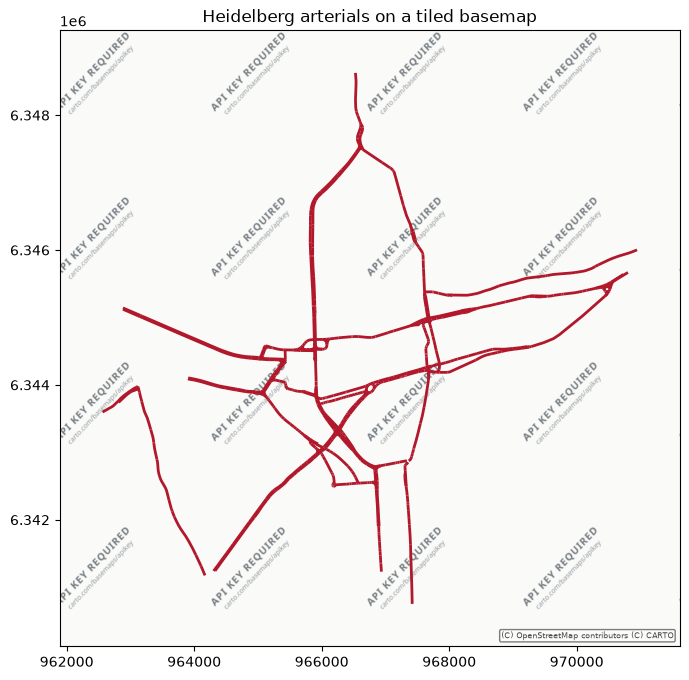

In [8]:
m = Map(crs=3857, figsize=(8, 8))
# Draw the data first, then frame on it: set_bounds takes DISPLAY-CRS units, and this map's are
# Web Mercator metres, not degrees. Framing on the layer avoids having to convert them by hand —
# and basemap() resolves its zoom from the framed extent, so the order matters.
m.lines(arterials, color="#b2182b", width=2.0)
m.set_bounds(padding=0.08)
m.basemap()
m.set_title("Heidelberg arterials on a tiled basemap")
m.fig;

The roads now sit on real terrain and settlement instead of white space, which is what a basemap is for: context
you did not have to source or style. `source=` selects a provider, `api_key=` passes a key for the keyed ones,
and `preset=` takes a provider dictionary.

A caveat worth keeping: tiles are someone else's cartography, at a fixed resolution, under their licence. Check
the attribution terms before publishing, and do not zoom past the level the provider serves.

## Takeaway

- `nightshade(when)` shades the night hemisphere; pass a **timezone-aware** datetime.
- `tissot(lons, lats, radius_m=...)` draws equal-ground-radius circles, turning projection distortion from an
  assertion into a measurement.
- `basemap()` adds XYZ tiles underneath, best in EPSG:3857, and is skipped offline rather than failing.
- All three decorate the globe rather than the data, so they belong under `set_global()` or an explicit framing.

That closes the scene-level tour. The per-plot-type gallery is under [`static/`](static/01_imshow.ipynb).